<a href="https://colab.research.google.com/github/SofiaSchweitzer/ml4amplitudes/blob/main/classifier_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Training a binary classifier for amplitudes

We want to study whether we can use a binary classifier to predict whether a scrambeled amplitude reduces to zero or not. In this setup, we treat reducing to zero as "signal" or class 1, and not reducing to zero as "background" or class 0.

#### Relevant papers
Learning the Simplicity of Scattering Amplitudes, <br> *Clifford Cheung, Aurélien Dersy, Matthew D. Schwartz* ,<br> https://arxiv.org/pdf/2408.04720

Learning to Unscramble:
Simplifying Symbolic Expressions via Self-Supervised Oracle Trajectories, <br> *David Shih*,<br>https://arxiv.org/pdf/2603.11164




Let's import relevant libaries

In [36]:
import torch
import torch.nn as nn
import time
import itertools
import re
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(device)

cuda


We will start by loading scrambled amplitudes from ...

In [3]:
!wget -q -O data.zip "https://www.dropbox.com/scl/fo/hvrw0aeegxfwv3tvp20vu/AGYOxx0IsiI2pL2mbmuHCh0?rlkey=snk2lmoxt61hj0dli7y4mgjqw&dl=1"
!unzip -o -q data.zip -d data 2>/dev/null; ls data

background.pkl	signal.pkl


In [4]:
bkg = np.load("data/background.pkl", allow_pickle=True)
sig = np.load("data/signal.pkl", allow_pickle=True)

### Exercise 1 - Study the data

Get familiar with the dataset. Do this by looking at the format and the structure of the expressions. What would you feed into the classifier?

In [5]:
for key in bkg.keys():
    print(key)

expression
simple_expression
num_scrambles
started_from_zero
source_file
source_index
info


In [6]:
bkg["expression"][0]

'(ab(1, 2)**2*ab(1, 4)**3*sb(1, 2)**3 + 2*ab(1, 2)*ab(1, 4)**3*ab(2, 3)*sb(1, 2)**2*sb(2, 3) + ab(1, 4)**3*ab(2, 3)**2*sb(1, 2)*sb(2, 3)**2)/(ab(1, 2)*ab(2, 4)*sb(1, 3)*sb(3, 4))'

Every expression is stored as `(numerator)/(denominator)`, where the denominator is a single product of brackets. The expression is zero exactly when the numerator is zero, so we only encode the numerator.
The numerator is a sum of terms, and each term is an integer coefficient times a product of brackets. With 4 particles there are only 12 possible brackets.

Now, a key ingredient to symbolic ML is to find a representation that is understandable for a classifier.

In our case, we can describe each term with 14 coefficients:
- `log(1 + |coefficient|)` and the sign of the coefficient
- the power of each of the 12 brackets (0 if the bracket is absent)

An expression has at most 10 numerator terms in this dataset.As we will start with a simple MLP, the input needs to be ordered and flattened. Therefore, we stack the terms into a 10 × 14 table, sort the rows so the order is always the same, fill unused rows with zeros, and flatten. Each expression becomes a vector of 140 numbers.

In [7]:
class TransformData:
    def __init__(self, n_point=4, max_terms=10):
        """
        Initializes the transformation from expression strings to feature vectors.

        Args:
            n_point (int): Number of external particles.
            max_terms (int): Maximum number of numerator terms, shorter expressions are zero-padded.
        """
        self.n_point = n_point
        self.max_terms = max_terms

        # All brackets ab(i, j) and sb(i, j) with i < j, one column each
        self.pairs = [(i, j) for i in range(1, n_point + 1) for j in range(i + 1, n_point + 1)]
        self.columns = [f"{t}{i}{j}" for t in ("ab", "sb") for i, j in self.pairs]
        self.col_index = {name: k for k, name in enumerate(self.columns)}

        # Coefficient (log magnitude and sign) plus one power per bracket
        self.term_dim = 2 + len(self.columns)
        self.dims_in = self.max_terms * self.term_dim

        self.bracket = re.compile(r"(ab|sb)\((\d), (\d)\)(?:\*\*(\d+))?")
        self.coeff = re.compile(r"^(-?)(\d+)?\*?")

    def split_numerator(self, expr):
        """
        Splits off the numerator of an expression.

        Args:
            expr (str): Expression of the form "(num)/(den)" or a polynomial without denominator.

        Returns:
            str: Numerator without outer brackets.
            bool: True if the numerator has an overall minus sign.
        """
        depth = 0
        for k, ch in enumerate(expr):
            depth += (ch == "(") - (ch == ")")
            if ch == "/" and depth == 0:
                num = expr[:k]
                break
        else:
            num = expr

        neg = num.startswith("-(")
        if neg:
            num = num[1:]
        if num.startswith("(") and num.endswith(")"):
            num = num[1:-1]
        return num, neg

    def encode_term(self, term, flip):
        """
        Encodes a single term as coefficient and bracket powers.

        Args:
            term (str): Term like "2*ab(1, 2)*sb(2, 3)**2".
            flip (bool): If True, flips the sign of the term.

        Returns:
            ndarray: Feature vector of size `self.term_dim`.
        """
        row = np.zeros(self.term_dim, dtype=np.float32)

        sign, digits = self.coeff.match(term).groups()
        c = int(digits) if digits else 1
        row[0] = np.log1p(c)
        row[1] = -1.0 if (sign == "-") != flip else 1.0

        for kind, i, j, p in self.bracket.findall(term):
            i, j = sorted((int(i), int(j)))
            row[2 + self.col_index[f"{kind}{i}{j}"]] += int(p) if p else 1
        return row

    def encode(self, expr):
        """
        Encodes an expression as a flat vector of its numerator terms.

        Args:
            expr (str): Expression string.

        Returns:
            ndarray: Feature vector of size `self.dims_in`.
        """
        num, flip = self.split_numerator(expr)
        terms = num.replace(" - ", " + -").split(" + ")

        # Sort the terms so that the input does not depend on their order
        rows = sorted((self.encode_term(t, flip) for t in terms), key=lambda r: r.tobytes())

        x = np.zeros((self.max_terms, self.term_dim), dtype=np.float32)
        x[:len(rows)] = rows[:self.max_terms]
        return x.ravel()

    def __call__(self, expressions):
        """
        Encodes a list of expressions.

        Args:
            expressions (list): Expression strings.

        Returns:
            Tensor: Features of shape (len(expressions), `self.dims_in`).
        """
        return torch.tensor(np.stack([self.encode(e) for e in expressions]))


Let's look at how this changes the expression

In [8]:
transform = TransformData()

print("coeff, sign,", ", ".join(transform.columns))
print(transform.encode(bkg["expression"][0]).reshape(transform.max_terms, transform.term_dim)[:4])

coeff, sign, ab12, ab13, ab14, ab23, ab24, ab34, sb12, sb13, sb14, sb23, sb24, sb34
[[0.6931472 1.        0.        0.        3.        2.        0.
  0.        1.        0.        0.        2.        0.        0.       ]
 [0.6931472 1.        2.        0.        3.        0.        0.
  0.        3.        0.        0.        0.        0.        0.       ]
 [1.0986123 1.        1.        0.        3.        1.        0.
  0.        2.        0.        0.        1.        0.        0.       ]
 [0.        0.        0.        0.        0.        0.        0.
  0.        0.        0.        0.        0.        0.        0.       ]]


We now apply the transformation to our datasets

In [9]:
t0 = time.time()

sig_data = transform(sig["expression"])
bkg_data = transform(bkg["expression"])
print(f"Signal {tuple(sig_data.shape)}, background {tuple(bkg_data.shape)}, encoded in {round(time.time() - t0, 1)}s")

Signal (261610, 140), background (238390, 140), encoded in 50.0s


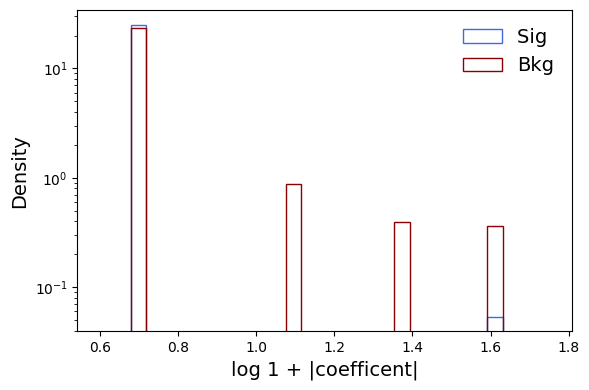

In [11]:
# Plot
plt.figure(figsize=(6, 4))
plt.hist(sig_data[:,0], bins=np.linspace(0.6,1.75,30), label="Sig ", density=True, color="royalblue", histtype="step")
plt.hist(bkg_data[:, 0], bins=np.linspace(0.6,1.75,30), label="Bkg", density=True, color="darkred", histtype="step")


plt.xlabel(r"log 1 + |coefficent|",
          fontsize=14)

plt.ylabel("Density",
        fontsize=14)

plt.yscale("log")
plt.legend(frameon=False, fontsize=14)
plt.tight_layout()
plt.show()

Lastly, we separate our datasets into test and train

In [26]:
sig_data = torch.tensor(sig_data, dtype=torch.float32 ,device=device)
bkg_data = torch.tensor(bkg_data, dtype=torch.float32, device=device)

sig_data_train, sig_data_test = sig_data[:150000], sig_data[150000:]
bkg_data_train, bkg_data_test = bkg_data[:150000], bkg_data[150000:]

/tmp/ipykernel_1258/3349949446.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  sig_data = torch.tensor(sig_data, dtype=torch.float32 ,device=device)
/tmp/ipykernel_1258/3349949446.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  bkg_data = torch.tensor(bkg_data, dtype=torch.float32, device=device)


### Exercise 2 – Building a Classifier in PyTorch

In this first exercise, we will implement a binary classifier using PyTorch.

The aim is to build a reusable classifier class. This modular design allows us to train and evaluate the classifier multiple times thoughout our tutorial.

#### Structure of the Classifier

Your classifier should be implemented as a Python class with the following components:

1. **Initialization (`__init__`)**  
   Here, we define:
   - `dims_in`: the number of input features,
   - `params`: a dictionary of hyperparameters (such as learning rate, network size, and number of training epochs).

2. **Building Network (`init_network`)**  
   Define a fully connected feedforward neural network with:
   - One input layer,
   - A configurable number of hidden layers using ReLU activations,
   - A final output layer with a single unit producing logits.

3. **Loss Function (`batch_loss`)**  
   Implement a method that computes the weighted binary cross-entropy loss for a given batch of:
   - input features `x`,
   - labels `y`

4. **Training Loop (`train_classifier`)**  
   Create a training loop that:
   - Accepts data (`sig_data`) and sim(`bkg_data`) samples,
   - Trains the classifier using the Adam optimizer and a learning rate scheduler.

5. **Evaluation (`evaluate`)**  
   Evaluate the classifier on new data and return either:
   - `exp(logit)`, which gives the likelihood ratio,
   - or `sigmoid(logit)`, which gives the predicted signal probability.


In [28]:
class Classifier(nn.Module):
    def __init__(self, dims_in, params):
        """
        Initializes the classifier model.

        Args:
            dims_in (int): Dimensionality of input features.
            params (dict): Dictionary of model and training hyperparameters.
        """
        super().__init__()
        self.dims_in = dims_in
        self.params = params
        self.init_network()

    def init_network(self):
        """
        Initializes a fully connected feedforward neural network.
        """
        # TODO:
        #    - Build a network to predict the class.
        #    - Use 3 hidden layers of size `self.params["hidden_layers"]`
        #    - The last layer need to map back to the class dimension

        self.net = nn.Sequential(
            nn.Linear(self.dims_in, self.params["hidden_layers"]),
            nn.ReLU(),
            nn.Linear(self.params["hidden_layers"], self.params["hidden_layers"]),
            nn.ReLU(),
            nn.Linear(self.params["hidden_layers"], self.params["hidden_layers"]),
            nn.ReLU(),
            nn.Linear(self.params["hidden_layers"], 1),
        )

    def batch_loss(self, x, y):
        """
        Computes the weighted BCE loss for a batch.

        Args:
            x (Tensor): Input features.
            y (Tensor): Labels (0 or 1).
            w (Tensor): Sample weights.

        Returns:
            Tensor: Scalar loss value.
        """
        # TODO: Implement the batch_loss function
        # Hint: You can use either torch.nn.BCEWithLogitsLoss or
        # torch.nn.BCE. What's the difference?

        pred = self.net(x).squeeze()
        loss = torch.nn.BCEWithLogitsLoss()(pred, y)
        return loss

    def train_classifier(self,
                         sig_data,
                         bkg_data):
        """
        Trains the classifier on provided signal (y=1) and background (y=0) data.

        Args:
            sig_data (Tensor): Data with label 1.
            bkg_data (Tensor): Data with label 0.
        """

        device = sig_data.device
        dtype = sig_data.dtype

        loader_sig = torch.utils.data.DataLoader(
            sig_data,
            batch_size=self.params["batch_size"], shuffle=True,
            )

        loader_bkg = torch.utils.data.DataLoader(
            bkg_data,
            batch_size=self.params["batch_size"], shuffle=True,
            )

        optimizer = torch.optim.Adam(self.net.parameters(), lr=self.params["lr"])
        scheduler = torch.optim.lr_scheduler.OneCycleLR(
            optimizer=optimizer,
            max_lr=self.params.get("max_lr", 3 * self.params["lr"]),
            epochs=self.params["n_epochs"],
            steps_per_epoch=min(len(loader_sig), len(loader_bkg)))

        print(f"Training classifier for {self.params['n_epochs']} epochs with lr {self.params['lr']}")
        t0 = time.time()

        for epoch in range(self.params["n_epochs"]):
            losses = []
            for x_sig, x_bkg in zip(loader_sig, loader_bkg):
                label_sig = torch.ones((x_sig.shape[0]), device=device, dtype=dtype)
                label_bkg = torch.zeros((x_bkg.shape[0]), device=device, dtype=dtype)
                # TODO: Write training loop

                # Reset optimizer
                optimizer.zero_grad()

                # Calculate batch loss once for true and fake
                loss = self.batch_loss(x_sig, label_sig)
                loss += self.batch_loss(x_bkg, label_bkg)

                # Backpropagate
                loss.backward()

                # Updata optimizer and scheduler
                optimizer.step()
                scheduler.step()

                losses.append(loss.item())

            if epoch % max(1, self.params["n_epochs"] // 5) == 0:
                print(f"    Epoch {epoch}: Avg loss = {torch.tensor(losses).mean():.4f}, Time = {round(time.time() - t0, 1)}s")

        print(f"Training finished in {round(time.time() - t0, 1)} seconds.")

    def evaluate(self, data, return_weights=False):
        """
        Evaluates the classifier.

        Args:
            data (Tensor): Input data.
            return_weights (bool): If True, returns likelihood ratios (exp(logits)).

        Returns:
            Tensor: Predicted weights or probabilities.
        """
        # TODO: Evaluate classifier and return weights or the classifier output
        predictions = []
        with torch.no_grad():
            for batch in torch.split(data, self.params["batch_size_sample"]):
                pred = self.net(batch).squeeze().detach()
                predictions.append(pred)
        predictions = torch.cat(predictions)
        return predictions.exp().clip(0, 30) if return_weights else torch.sigmoid(predictions)

### Exercise 3 - Train classifier and evaluate performance

In [29]:
# Define classifier parameteres

classifier_params = {"hidden_layers": 256,
                     "lr": 1.e-3,
                     "n_epochs" : 10,
                     "batch_size" : 512,
                     "batch_size_sample": 2000}

1. Train a classifier between signal and background

In [30]:
# Build the classifier
classifier = Classifier(dims_in=140, params=classifier_params).to(device)

# Train the classifier
classifier.train_classifier(
    sig_data=sig_data_train,
    bkg_data=bkg_data_train
)

Training classifier for 10 epochs with lr 0.001
    Epoch 0: Avg loss = 1.1348, Time = 1.6s
    Epoch 2: Avg loss = 0.5134, Time = 5.7s
    Epoch 4: Avg loss = 0.3431, Time = 9.1s
    Epoch 6: Avg loss = 0.2529, Time = 13.3s
    Epoch 8: Avg loss = 0.1833, Time = 19.1s
Training finished in 20.7 seconds.


2. Evaluate classifier on train and test dataset

In [33]:
pred_train = classifier.evaluate(
    data=torch.cat([sig_data_train, bkg_data_train])
)
pred_test = classifier.evaluate(
    data=torch.cat([sig_data_test, bkg_data_test])
)

3. Compare to true labels

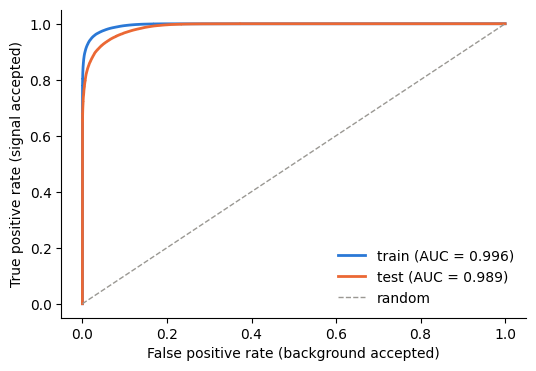

In [39]:
# Labels in the same order as the concatenation: signal (1) first, then background (0)
y_train = torch.cat([torch.ones(len(sig_data_train)), torch.zeros(len(bkg_data_train))])
y_test = torch.cat([torch.ones(len(sig_data_test)), torch.zeros(len(bkg_data_test))])

fig, ax = plt.subplots(figsize=(6, 4))
for name, y, pred, color in [("train", y_train, pred_train, "#2a78d6"),
                              ("test", y_test, pred_test, "#eb6834")]:
    fpr, tpr, _ = roc_curve(y.cpu(), pred.cpu())
    auc = roc_auc_score(y.cpu(), pred.cpu())
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], color="#9a9893", lw=1, ls="--", label="random")

ax.set_xlabel("False positive rate (background accepted)")
ax.set_ylabel("True positive rate (signal accepted)")

ax.legend(frameon=False, loc="lower right")

for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()